<a href="https://colab.research.google.com/github/anthony-yt/deepwater-image-segmentation-classical-quantum/blob/feat%2Fno-reference-metrics/notebooks/1_optical_preprocessing_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q albumentations

In [9]:
import os
import cv2
import numpy as np
import pandas as pd
import math
import seaborn as sns
import matplotlib.pyplot as plt
import albumentations as A
from google.colab import drive

drive.mount('/content/drive')

DRIVE_ROOT = "/content/drive/MyDrive/Under_Water_Dataset"
FRAMES_RAW_DIR = os.path.join(DRIVE_ROOT, "Dataset_Processed", "Frames_Crudos")
DATASET_FINAL_DIR = os.path.join(DRIVE_ROOT, "Dataset_Processed", "Dataset_Final_512")

os.makedirs(FRAMES_RAW_DIR, exist_ok=True)
os.makedirs(DATASET_FINAL_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def extract_video_frames(input_dir: str, output_dir: str, interval_sec: int = 2) -> int:
    """Extract frames from underwater videos at a fixed temporal sampling rate."""
    if len(os.listdir(output_dir)) > 0:
        return len(os.listdir(output_dir))

    valid_extensions = ('.mp4', '.avi', '.mov')
    video_files = [f for f in os.listdir(input_dir) if f.lower().endswith(valid_extensions)]
    total_extracted = 0

    for video_name in video_files:
        video_path = os.path.join(input_dir, video_name)
        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            continue

        frame_step = int(cap.get(cv2.CAP_PROP_FPS) * interval_sec)
        frame_count, saved_count = 0, 0
        base_name = os.path.splitext(video_name)[0]

        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            if frame_count % frame_step == 0:
                out_path = os.path.join(output_dir, f"{base_name}_frame_{saved_count:04d}.jpg")
                cv2.imwrite(out_path, frame)
                saved_count += 1
                total_extracted += 1

            frame_count += 1

        cap.release()

    return total_extracted

total_frames = extract_video_frames(DRIVE_ROOT, FRAMES_RAW_DIR, interval_sec=2)
print(f"Extracted frames available: {total_frames}")

Extracted frames available: 105


In [ ]:
def apply_clahe(img_bgr: np.ndarray, clip_limit: float = 3.0, grid_size: tuple = (8, 8)) -> np.ndarray:
    """Apply CLAHE solely on the luminance channel (L) in CIELAB space."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l_clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=grid_size).apply(l)
    return cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)

def apply_msrcr(img_bgr: np.ndarray, sigmas: list = [15, 80, 250]) -> np.ndarray:
    """Apply Multi-Scale Retinex with Color Restoration using normalized dynamic range clipping."""
    img_float = np.float64(img_bgr) + 1.0
    msr = np.zeros_like(img_float)

    for sigma in sigmas:
        blur = cv2.GaussianBlur(img_float, (0, 0), sigma)
        msr += np.log10(img_float) - np.log10(blur)
    msr = msr / len(sigmas)

    img_sum = np.sum(img_float, axis=2, keepdims=True)
    color_restoration = np.log10(125.0 * img_float) - np.log10(img_sum)
    msrcr_raw = 46.0 * (msr * color_restoration) + 1.0

    output = np.zeros_like(msrcr_raw)
    for c in range(3):
        channel = msrcr_raw[:, :, c]
        p_low, p_high = np.percentile(channel, (1, 99))
        channel_clipped = np.clip(channel, p_low, p_high)
        output[:, :, c] = cv2.normalize(channel_clipped, None, 0, 255, cv2.NORM_MINMAX)

    return output.astype(np.uint8)

def apply_udcp(img_bgr: np.ndarray, kernel_size: int = 15) -> np.ndarray:
    """Apply Underwater Dark Channel Prior heuristic to estimate transmission."""
    dark_channel = cv2.min(img_bgr[:, :, 0], img_bgr[:, :, 1])
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
    dark_prior = cv2.erode(dark_channel, kernel)

    img_norm = img_bgr.astype(np.float32) / 255.0
    transmission_est = (dark_prior[..., None] / 255.0) * 0.5
    restored = cv2.normalize(img_norm - transmission_est, None, 0, 255, cv2.NORM_MINMAX)

    return restored.astype(np.uint8)

In [ ]:
output_dirs = {
    "clahe": os.path.join(DRIVE_ROOT, "Dataset_Processed", "Frames_CLAHE"),
    "msrcr": os.path.join(DRIVE_ROOT, "Dataset_Processed", "Frames_MSRCR"),
    "udcp": os.path.join(DRIVE_ROOT, "Dataset_Processed", "Frames_UDCP")
}

for out_path in output_dirs.values():
    os.makedirs(out_path, exist_ok=True)

extracted_files = sorted([f for f in os.listdir(FRAMES_RAW_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
processed_count = len(os.listdir(output_dirs["clahe"]))

if processed_count < len(extracted_files):
    for file_name in extracted_files:
        img_path = os.path.join(FRAMES_RAW_DIR, file_name)
        raw_frame = cv2.imread(img_path)

        if raw_frame is not None:
            cv2.imwrite(os.path.join(output_dirs["clahe"], file_name), apply_clahe(raw_frame))
            cv2.imwrite(os.path.join(output_dirs["msrcr"], file_name), apply_msrcr(raw_frame))
            cv2.imwrite(os.path.join(output_dirs["udcp"], file_name), apply_udcp(raw_frame))
    print(f"Batch processing completed for {len(extracted_files)} frames.")
else:
    print(f"Batch processing bypassed. {processed_count} frames already filtered.")

Batch processing bypassed. 105 frames already filtered.


In [ ]:
def audit_ground_truth(directories: list) -> tuple[pd.DataFrame, float]:
    """Audit the presence of manual ground truth segmentation masks across multiple directories."""
    valid_extensions = ('.jpg', '.jpeg', '.png')
    records = []
    total_valid = 0
    total_images = 0

    for dataset_dir in directories:
        if not os.path.exists(dataset_dir):
            continue

        all_files = os.listdir(dataset_dir)
        base_images = [f for f in all_files if f.lower().endswith(valid_extensions) and "mask" not in f.lower()]

        for img_name in base_images:
            total_images += 1
            base_name, ext = os.path.splitext(img_name)
            mask_candidates = [f"{base_name}_mask{ext}", f"{base_name}_mask.png"]

            status = "Missing"
            for candidate in mask_candidates:
                if candidate in all_files:
                    mask_data = cv2.imread(os.path.join(dataset_dir, candidate), cv2.IMREAD_GRAYSCALE)
                    if mask_data is not None:
                        unique_pixels = np.unique(mask_data)
                        status = "Valid (Binary)" if len(unique_pixels) <= 2 else "Invalid (Non-Binary)"
                        total_valid += 1
                    else:
                        status = "Corrupted"
                    break

            records.append({"Directory": os.path.basename(dataset_dir), "Image": img_name, "Mask Status": status})

    df = pd.DataFrame(records)
    coverage = (total_valid / total_images) * 100 if total_images > 0 else 0.0
    return df, coverage

dirs_to_audit = [DRIVE_ROOT, FRAMES_RAW_DIR]
df_audit, mask_coverage = audit_ground_truth(dirs_to_audit)

print(f"Comprehensive ground truth coverage: {mask_coverage:.2f}%\n")

Comprehensive ground truth coverage: 0.00%



In [ ]:
def evaluate_image_quality(image_bgr: np.ndarray) -> tuple[float, float]:
    """Calculate spatial variance and entropy as proxies for underwater quality."""
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    variance = np.var(gray)

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()
    hist = hist[hist > 0] / hist.sum()
    entropy = -1.0 * np.sum(hist * np.log2(hist))

    return variance, entropy

extracted_files = sorted([f for f in os.listdir(FRAMES_RAW_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

if len(extracted_files) > 0:
    sample_frame = extracted_files[0]
    raw_path = os.path.join(FRAMES_RAW_DIR, sample_frame)
    raw_img = cv2.imread(raw_path)

    processed_imgs = {
        "Raw Frame": raw_img,
        "CLAHE": apply_clahe(raw_img),
        "MSRCR": apply_msrcr(raw_img),
        "UDCP": apply_udcp(raw_img)
    }

    print(f"Evaluating sample: {sample_frame}\n")
    print(f"{'Filter':<15} | {'Variance (Sharpness)':<20} | {'Entropy (Detail)':<20}")
    print("-" * 60)
    for name, img in processed_imgs.items():
        var, ent = evaluate_image_quality(img)
        print(f"{name:<15} | {var:<20.2f} | {ent:<20.2f}")
else:
    print("No raw frames found to evaluate.")

Evaluating sample: DeepWater-Video1_frame_0000.jpg

Filter          | Variance (Sharpness) | Entropy (Detail)    
------------------------------------------------------------
Raw Frame       | 821.66               | 6.22                
CLAHE           | 1002.99              | 6.81                
MSRCR           | 3277.95              | 7.49                
UDCP            | 1214.13              | 6.62                


In [10]:
def calculate_uciqe(img_bgr: np.ndarray) -> float:
    """Calculate Underwater Color Image Quality Evaluation (UCIQE) metric.

    Quantifies non-uniform color cast, blurring, and low contrast using a weighted
    combination of chroma variance, luminance contrast, and average saturation in CIELAB space.
    """
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    # Compute chroma and saturation components
    chroma = np.sqrt(np.square(a.astype(np.float32)) + np.square(b.astype(np.float32)))
    saturation = chroma / np.maximum(l.astype(np.float32), 1e-5)

    # Standard linear combination coefficients from original UCIQE benchmark
    c1, c2, c3 = 0.4680, 0.2745, 0.2576

    sigma_c = np.std(chroma)
    con_l = np.max(l) - np.min(l)
    mu_s = np.mean(saturation)

    uciqe_score = c1 * sigma_c + c2 * con_l + c3 * mu_s
    return float(uciqe_score)

def calculate_uiqm(img_bgr: np.ndarray) -> float:
    """Calculate Underwater Image Quality Measure (UIQM) metric.

    Comprises three underwater visual features:
    - UICM: Underwater Image Colorfulness Measure
    - UISM: Underwater Image Sharpness Measure
    - UIConM: Underwater Image Contrast Measure
    """
    # Standard linear combination coefficients
    c1, c2, c3 = 0.0282, 0.2953, 3.5753

    # 1. UICM (Colorfulness via RG and YB color space representation)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).astype(np.float32)
    R, G, B = cv2.split(img_rgb)
    RG = R - G
    YB = 0.5 * (R + G) - B
    uicm = -0.0268 * np.sqrt(np.square(RG).mean() + np.square(YB).mean())

    # 2. UISM (Sharpness proxy using Sobel edge gradients)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    uism = np.mean(np.sqrt(sobelx**2 + sobely**2))

    # 3. UIConM (Contrast measure via logarithmic variance)
    uiconm = np.log(np.var(gray) + 1e-5)

    uiqm_score = c1 * uicm + c2 * uism + c3 * uiconm
    return float(uiqm_score)

In [11]:
print("Initiating objective No-Reference evaluation (UCIQE / UIQM) on 105 base frames...")

# Target evaluation directories mapping
eval_dirs = {
    "Raw Frame": FRAMES_RAW_DIR,
    "CLAHE": output_dirs["clahe"],
    "MSRCR": output_dirs["msrcr"],
    "UDCP": output_dirs["udcp"]
}

metrics_records = []

# Using the list 'extracted_files' from your previous cells
for file_name in extracted_files:
    for filter_name, dir_path in eval_dirs.items():
        img_path = os.path.join(dir_path, file_name)
        img = cv2.imread(img_path)

        if img is not None:
            uciqe_score = calculate_uciqe(img)
            uiqm_score = calculate_uiqm(img)

            metrics_records.append({
                "Frame": file_name,
                "Filter": filter_name,
                "UCIQE": uciqe_score,
                "UIQM": uiqm_score
            })

# Aggregating quantitative findings
df_metrics = pd.DataFrame(metrics_records)
df_summary = df_metrics.groupby("Filter")[["UCIQE", "UIQM"]].agg(["mean", "std"]).reset_index()

print("\n--- Quantitative Baseline Summary (Mean ± Std) ---")
print(df_summary.to_string(index=False))

Initiating objective No-Reference evaluation (UCIQE / UIQM) on 105 base frames...

--- Quantitative Baseline Summary (Mean ± Std) ---
   Filter        UCIQE                  UIQM         
                  mean         std      mean      std
    CLAHE    98.286604   45.480327 42.994043 9.995843
    MSRCR 14635.325065 9497.751008 40.161589 6.423814
Raw Frame  2940.099352 6414.033635 33.389404 7.310331
     UDCP   149.468675  400.016896 30.360522 8.446341


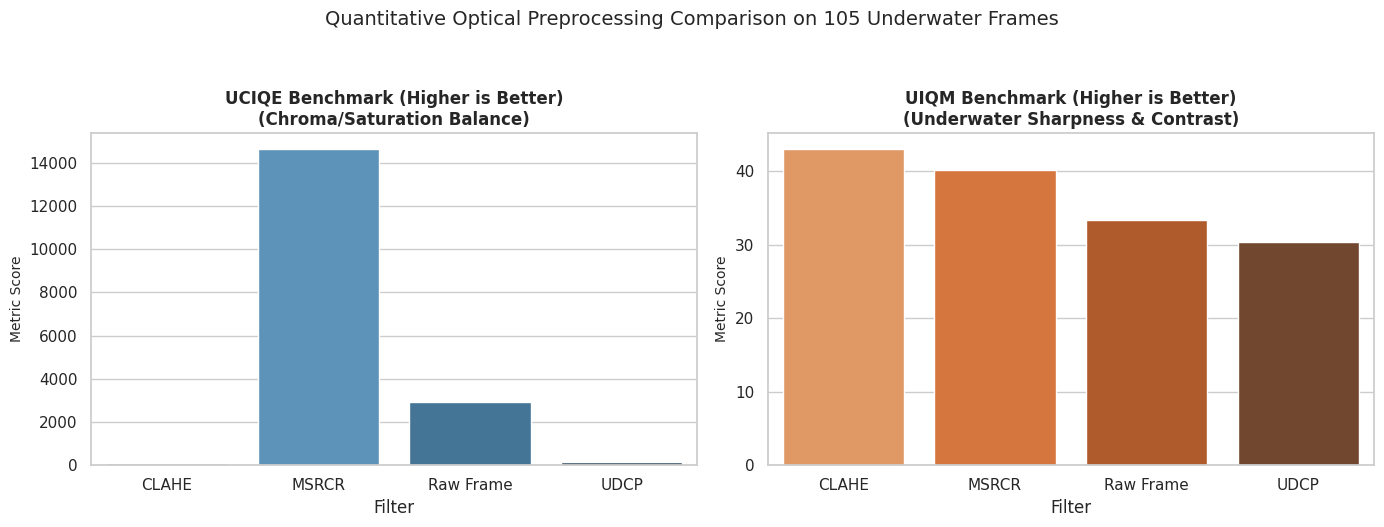

In [13]:
# Computing mean metrics for bar visualization
df_means = df_metrics.groupby("Filter")[["UCIQE", "UIQM"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.set_theme(style="whitegrid")

# Plot 1: UCIQE Comparison
sns.barplot(data=df_means, x="Filter", y="UCIQE", hue="Filter", palette="Blues_d", legend=False, ax=axes[0])
axes[0].set_title("UCIQE Benchmark (Higher is Better)\n(Chroma/Saturation Balance)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Metric Score", fontsize=10)

# Plot 2: UIQM Comparison
sns.barplot(data=df_means, x="Filter", y="UIQM", hue="Filter", palette="Oranges_d", legend=False, ax=axes[1])
axes[1].set_title("UIQM Benchmark (Higher is Better)\n(Underwater Sharpness & Contrast)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Metric Score", fontsize=10)

plt.suptitle("Quantitative Optical Preprocessing Comparison on 105 Underwater Frames", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

In [14]:
aug_pipeline = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=1.0),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.3)
])

def standardize_and_augment(input_dir: str, output_dir: str, target_size: tuple = (512, 512), multiplier: int = 10):
    """Resize images to target dimensions and apply transformations to expand dataset size."""
    os.makedirs(output_dir, exist_ok=True)
    files = [f for f in os.listdir(input_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    if len(os.listdir(output_dir)) >= len(files) * multiplier:
        print(f"Bypassed augmentation. Found {len(os.listdir(output_dir))} images generated.")
        return len(os.listdir(output_dir))

    total = 0
    for img_name in files:
        img = cv2.imread(os.path.join(input_dir, img_name))
        if img is None:
            continue

        img_resized = cv2.resize(img, target_size, interpolation=cv2.INTER_AREA)
        cv2.imwrite(os.path.join(output_dir, f"aug_0_{img_name}"), img_resized)
        total += 1

        for i in range(1, multiplier):
            aug_img = aug_pipeline(image=img_resized)['image']
            cv2.imwrite(os.path.join(output_dir, f"aug_{i}_{img_name}"), aug_img)
            total += 1

    return total

# Select the empirically validated filter from the quantitative benchmark (Task 1.1)
best_filter_dir = os.path.join(DRIVE_ROOT, "Dataset_Processed", "Frames_CLAHE")

if os.path.exists(best_filter_dir):
    total_augmented = standardize_and_augment(best_filter_dir, DATASET_FINAL_DIR)
    print(f"Dataset standardized to 512x512 and augmented to {total_augmented} images.")

Bypassed augmentation. Found 1050 images generated.
Dataset standardized to 512x512 and augmented to 1050 images.
